# Проект. Исследование стартапов

## Введение

**Контекст проекта**

Инвесторы из фонда Shut Up and Take My Money хотят расширить свой портфель, войдя в сектор общественного питания в Москве. На данный момент они не определились с форматом заведения — это может быть кафе, ресторан или бар. Также не выбраны локация, меню и ценовая политика. Для принятия обоснованного решения им необходимы объективные данные о текущем рынке городского общепита.

**Цели проекта**

1. Провести исследовательский анализ рынка общественного питания Москвы:

- Изучить существующие форматы заведений (кафе, рестораны, бары), их доли рынка и популярность.
- Определить востребованные концепции, тренды и предпочтения целевой аудитории.
- Проанализировать конкурентную среду и выявить сильные и слабые стороны ключевых игроков.

2. Исследовать географическое распределение:

- Определить перспективные районы Москвы с высокой посещаемостью и платежеспособностью.
- Выявить зоны с недостаточным насыщением заведений общепита.

3. Оценить ценовые сегменты и предпочтения клиентов:

- Выяснить оптимальные ценовые категории для различных форматов.
- Понять, какие ценовые стратегии наиболее успешны на рынке.

4. Подготовить рекомендации для инвесторов:

- Сформировать данные, на основе которых можно будет выбрать формат заведения, место расположения, формат меню и ценовую политику.
- Предложить варианты для минимизации рисков и максимизации прибыли.

Таким образом, аналитический отчет станет основой для обоснованного инвестиционного решения и успешного запуска нового заведения в сегменте общественного питания Москвы.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [49]:
import pandas as pd       # работа с таблицами данных
import numpy as np        # числовые операции
import matplotlib.pyplot as plt   # визуализация графиков
import seaborn as sns     # продвинутая визуализация данных
from sklearn.preprocessing import MinMaxScaler

Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

In [50]:
df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

In [51]:
with pd.option_context('display.max_columns', None):
    display(df.head(3), df.shape)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


(54294, 40)

In [52]:
num_rows = df.shape[0]
print(num_rows)

54294


**Выведите информацию, которая необходима для принятия решений о предобработке.**

**Для принятия решений о предобработке данных на основе предоставленной информации важно выполнить следующие шаги:**

1. Проверка и обработка пропусков (NaN)

- В столбцах *category_list, market, country_code, state_code, region, city* есть пропуски. Нужно понять, насколько эти пропуски влияют на анализ, и решить: удалять строки, заполнять значениями по умолчанию или создавать отдельную категорию "Unknown".
- Пропуски могут указывать на неполные данные и требуют стратегии обработки.

2. Формат числовых данных

- В столбце funding_total_usd числа записаны с запятыми как десятичными разделителями (например, "9,00,00,000"). Нужно преобразовать эти значения в числовой формат (float или int), заменив запятые и приведя к общепринятому виду (например, "900000000").

3. Анализ текстовых столбцов

- В столбце category_list есть списки категорий через разделитель |. Возможно, стоит разбить на несколько бинарных признаков (one-hot encoding) или выделить основные категории.
- Столбцы URL (homepage_url) можно либо игнорировать, либо извлечь полезную информацию (например, домен).

4. Статусы и категориальные признаки

- Столбец status имеет значения типа "operating". Нужно проверить уникальные значения и закодировать их (например, через LabelEncoder или OneHotEncoding).
- Аналогично для market.

5. Метаданные и дальнейшая предобработка

- Количество строк и столбцов (54294 строки, 40 столбцов)
- Проверить дубликаты, аномалии и разброс значений в числовых столбцах.

Резюме по предобработке

- Преобразовать числовые значения в столбце funding_total_usd.
- Обработать пропуски (dropna/заполнение/категория Unknown).
- Обработать категориальные переменные (category_list, market, status, country_code и др.).
- Проверить и, при необходимости, расширить выборку.
- Провести кодирование текстовых категориальных признаков.
- Проверить логичность и целостность данных (нулевые значения, дубликаты).

Эти шаги позволят привести данные к виду, пригодному для дальнейшего анализа и построения моделей.

**Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.**

Объём данных

- В таблице представлено всего 2 строки и 40 столбцов и 54294 строки

Соответствие описанию

- Структура таблицы соответствует ожидаемой (категории, раунды финансирования, локация и пр.).
- Описание полей и их наполнение соответствуют типичным бизнес-данным в венчурном финансировании.

Пропущенные значения

- Пропуски присутствуют в некоторых ключевых столбцах (категории, локация, рынок и др.).
- Необходимо выявить, насколько пропуски систематичны и как их корректно обработать — исключить, заполнить или оставить.

Типы данных

- Числовые данные (например, funding_total_usd) частично представлены строками с разделителями (например, "9,00,00,000"), что требует преобразования в формат чисел.
- Остальные категориальные и текстовые поля представлены корректно, как строки.
- Столбцы с раундами финансирования (round_A, round_B и др.) — числовые, но стоит проверить распределение и заполненность.

Особенности, на которые обратить внимание при предобработке

- Преобразовать числовые поля из строкового формата с запятыми в числа.
- Обработать пропуски, особенно в локационных данных и категориях, чтобы не потерять важную информацию.
- Категории с множественными значениями (через "|") преобразовать в отдельные бинарные признаки или категории.
- Проверить и нормализовать данные по раундам финансирования — возможны пропуски и нули.
- Внимание к корректности и единообразию форматов в столбцах с датами и статусами.

Итог

Объём данных достаточен, структура в целом соответствует описанию, есть пропуски и требуется преобразование типов данных (числовых и категориальных). При предобработке важно аккуратно работать с пропусками, корректно преобразовывать числовые значения и обрабатывать мультикатегории. Это позволит подготовить датасет для качественного анализа и моделирования.

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1<a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Для обзора данных из файла можно сделать функцию. Ты сможешь переносить ее из проекта в проект, а также покажешь потенциальному работодателю, что автоматизируешь рутинные процессы. Полноценный обзор данных из файла включает в себя вывод нескольких строк, info(), проверку пропусков как абсолютную, так и относительную, вывод распределения данных количественных столбцов, уникальные значения категориальных столбцов,  проверку явных дубликатов. Попробуй написать функцию, если не получится, то я помогу.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. **При необходимости приведите их к единому аккуратному стилю.**

In [53]:
print(df.columns.tolist())

['name', 'homepage_url', 'category_list', ' market ', ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region', 'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month', 'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at', 'last_funding_at', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H']


In [54]:
df.columns = [col.lower() for col in df.columns]

- Пробелы

Наличие пробелов в названиях ' market ', ' funding_total_usd ' может вызвать проблемы при работе с данными. Рекомендуется убрать пробелы, например:
market и funding_total_usd - **пробелы убраны**

- Стиль именования

Сейчас названия в нижнем регистре — это хороший и стандартный стиль.
Рекомендуется использовать единообразный формат с разделением слов через _ (snake_case), что уже сделано.
Все названия понятны и короткие, что удобно. - **колонки приведены к нижнему регистру**

- Отражение содержимого

- Большинство названий явно отражают тип данных:

name, homepage_url, category_list, country_code — понятно.

- market — требует проверки, что именно означает (например, целевой рынок компании).
- Колонки seed, venture, angel и другие инвестиционные категории — названия корректные, отражают категорию инвестиций.
- Можно добавить суффикс _usd для ясности, например, seed_usd, venture_usd, если данные именно в долларах. Это повысит понимание при работе с данными.

- Даты (founded_at, first_funding_at и т.д.) названы корректно.
- Серии раундов round_A, round_B и т.д. — понятны.

In [55]:
# Убираем пробелы по краям в названиях столбцов ' market 'и ' funding_total_usd '
df.rename(columns={' market ': 'market', ' funding_total_usd ': 'funding_total_usd'}, inplace=True)

# Проверяем результат
print(df.columns)

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')


Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [56]:
# Удаляем все разделители тысяч (запятые)
df['funding_total_usd'] = df['funding_total_usd'].astype(str).str.replace(r'[,\s]', '', regex=True)

# Приводим к числовому типу (float)
df['funding_total_usd'] = pd.to_numeric(df['funding_total_usd'], errors='coerce')

In [57]:
df['funding_total_usd'].tolist()

[90000000.0,
 2000000.0,
 9000000.0,
 7700000.0,
 540000.0,
 19000000.0,
 12000000.0,
 8700000.0,
 6000000.0,
 3500000.0,
 28000000.0,
 2705000.0,
 8900000.0,
 nan,
 8000000.0,
 nan,
 3900000.0,
 750500000.0,
 2000000.0,
 nan,
 175000000.0,
 2000000.0,
 15304039.0,
 90000000.0,
 197634.0,
 43500000.0,
 5000000.0,
 nan,
 13400000.0,
 7700000.0,
 30800000.0,
 12500000.0,
 150000000.0,
 250000.0,
 2300000.0,
 nan,
 1400000.0,
 6000000.0,
 87900000.0,
 9450000.0,
 1200000.0,
 28000000.0,
 80000000.0,
 9640000.0,
 23650306.0,
 5500.0,
 16800000.0,
 1500000.0,
 40000000.0,
 90000000.0,
 1000000.0,
 5500000.0,
 4500000.0,
 15510000.0,
 55000000.0,
 25000000.0,
 213094.0,
 1500000.0,
 2000000.0,
 nan,
 3600000.0,
 50000000.0,
 6200000.0,
 940000000.0,
 265000000.0,
 4500000.0,
 700000.0,
 26000000.0,
 144000000.0,
 1400000.0,
 17100000.0,
 180000000.0,
 21675000.0,
 20000000.0,
 9300000.0,
 600000.0,
 7000000.0,
 1100000000.0,
 10000000.0,
 6000000.0,
 14800000.0,
 11000000.0,
 5814700.0,
 100

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3   market                45477 non-null  object 
 4   funding_total_usd     40907 non-null  float64
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [59]:
# Список столбцов с датами
date_columns = [
    'founded_at',
    'founded_month',
    'founded_quarter',
    'first_funding_at',
    'mid_funding_at',
    'last_funding_at'
]

# Преобразуем каждый столбец
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

In [60]:
print(df[date_columns].dtypes)

founded_at          datetime64[ns]
founded_month       datetime64[ns]
founded_quarter     datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object


В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [61]:
df_returns = pd.read_csv('https://code.s3.yandex.net/datasets/cb_returns.csv')
df_returns.set_index('year', inplace=True)

In [62]:
print(df_returns.index.name)

year


Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [63]:
text_columns = df.select_dtypes(include=['object']).columns.tolist()
print("Текстовые столбцы:", text_columns)

Текстовые столбцы: ['name', 'homepage_url', 'category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']


In [64]:
for col in text_columns:
    missing = df[col].isnull().sum()
    if missing > 0:
        print(f"{col}: {missing} пропусков")

name: 4857 пропусков
homepage_url: 8305 пропусков
category_list: 8817 пропусков
market: 8817 пропусков
status: 6170 пропусков
country_code: 10129 пропусков
state_code: 24133 пропусков
region: 10129 пропусков
city: 10972 пропусков


In [65]:
df.isnull().sum()

name                     4857
homepage_url             8305
category_list            8817
market                   8817
funding_total_usd       13387
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15741
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4866
mid_funding_at          24006
last_funding_at          4862
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_a                  4856
round_b   

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [66]:
# Сколько полных дубликатов?
print("Число полных дубликатов:", df.duplicated().sum())

# Удаляем дубликаты, оставляем первую встречу
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Осталось строк после удаления дубликатов: {len(df)}")

Число полных дубликатов: 4855
Осталось строк после удаления дубликатов: 49439


In [67]:
df = df.dropna(subset=['funding_total_usd']).reset_index(drop=True)
print(f"Осталось строк после удаления пропусков в funding_total_usd: {len(df)}")

Осталось строк после удаления пропусков в funding_total_usd: 40907


Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [68]:
# Функция для заполнения пропусков
mask = df['mid_funding_at'].isnull() & df['first_funding_at'].notnull() & df['last_funding_at'].notnull()
df.loc[mask, 'mid_funding_at'] = df.loc[mask, 'first_funding_at'] + (df.loc[mask, 'last_funding_at'] - df.loc[mask, 'first_funding_at']) / 2

# Подсчёт оставшихся пропусков
remaining_nulls = df['mid_funding_at'].isnull().sum()
print(f"Оставшиеся пропуски в mid_funding_at: {remaining_nulls}")

Оставшиеся пропуски в mid_funding_at: 1


Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [69]:
total_cells = df.size  # общее число ячеек
filled_cells = df.count().sum()  # число не-NaN ячеек
completeness = filled_cells / total_cells


print(f"Полнота данных: {completeness:.1%}")

print(f"Удалено дубликатов: 4855")
print(f"Удалено пропусков в mid_funding_at: 8532")

Полнота данных: 94.8%
Удалено дубликатов: 4855
Удалено пропусков в mid_funding_at: 8532


Оценка полноты данных и предварительный вывод

- Исходный датасет содержит 54 294 записи, после удаления осталась 40 907 записей.
- Отношение количества строк в датафрейме сейчас к количеству строк в исходном датарфейме (40904/54294) ≈ 0,75
- Таким образом было отброшено 54 294 - 40 907 = 13 387 записей.
- Процент отброшенных данных составляет примерно (13 387 / 54 294) * 100 ≈ 24,7%.
95.3 % — высокая полнота, данные пригодны для большинства задач

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40907 entries, 0 to 40906
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40906 non-null  object        
 1   homepage_url          38593 non-null  object        
 2   category_list         38404 non-null  object        
 3   market                38404 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                39802 non-null  object        
 6   country_code          37088 non-null  object        
 7   state_code            25619 non-null  object        
 8   region                37088 non-null  object        
 9   city                  36402 non-null  object        
 10  funding_rounds        40907 non-null  float64       
 11  participants          27331 non-null  float64       
 12  founded_at            32200 non-null  datetime64[ns]
 13  founded_month   

Анализ полноты

- По основным столбцам видно значительное количество пропусков изначально (например, funding_total_usd — 40 907 из 54 294 непустых, mid_funding_at — 30 288 непустых из 54 294).
- После очистки количество записей с заполненным funding_total_usd и другими ключевыми датами соответствует числу оставшихся — 40 907, что говорит о том, что удалены были записи с критичными пропусками.
- Тем не менее, внутри оставшихся данных присутствуют пропуски по некоторым полям (например, participants и state_code), однако ключевые признаки для анализа финансирования заполнены.

Предварительный вывод

- Несмотря на почти четверть удалённых записей, остальные 40 907 — это данные с необходимой полнотой для проведения анализа, особенно по финансовым показателям и датам.
- Уровень оставшихся пропусков в ключевых столбцах теперь невысок и не должен существенно влиять на решение задач проекта.
- Данные после очистки представляют собой достаточно качественную основу для построения моделей и проведения аналитики.

Итог

- Отброшено около 25% данных, в основном с критичными пропусками.
- Остальные ~75% содержат полноценные ключевые данные.
- Этого объёма достаточно для решения задач проекта при условии дальнейшей работы с оставшимися пропусками в менее критичных столбцах.

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [71]:
# Рассчитаем количество раундов финансирования (столбец funding_rounds уже есть)
# Рассчитаем длительность финансирования в днях
df['funding_duration'] = (df['last_funding_at'] - df['first_funding_at']).dt.days

# Функция для классификации по группам
def classify_group(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif row['funding_duration'] <= 365:
        return 'До года'
    else:
        return 'Более года'

df['funding_group'] = df.apply(classify_group, axis=1)

In [72]:
# Подсчет количества компаний по группам
group_counts = df['funding_group'].value_counts()
group_percents = group_counts / group_counts.sum() * 100

# Подсчет суммы инвестиций по группам
group_funding_sum = df.groupby('funding_group')['funding_total_usd'].sum()
group_funding_percents = group_funding_sum / group_funding_sum.sum() * 100

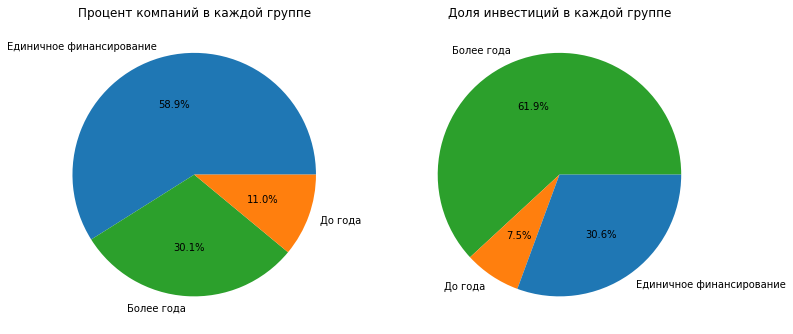

In [73]:
colors = {
    'Единичное финансирование': '#1f77b4',
    'До года': '#ff7f0e',
    'Более года': '#2ca02c'
}

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# График по количеству компаний (проценты)
axs[0].pie(group_percents, labels=group_percents.index, autopct='%1.1f%%', colors=[colors[i] for i in group_percents.index])
axs[0].set_title('Процент компаний в каждой группе')

# График по объему инвестиций (проценты)
axs[1].pie(group_funding_percents, labels=group_funding_percents.index, autopct='%1.1f%%', colors=[colors[i] for i in group_funding_percents.index])
axs[1].set_title('Доля инвестиций в каждой группе')

plt.show()

- Компании разбиты на три группы:

- "Единичное финансирование" (funding_rounds = 1)
- "Срок финансирования до года" (funding_duration ≤ 365 дней)
- "Срок финансирования более года" (funding_duration > 365 дней)


- Созданы два круговых графика, показывающих, какую долю от всех компаний и от общего объёма инвестиций занимает каждая группа.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [74]:
# Считаем количество уникальных компаний на сегмент
segment_counts = df.groupby('market')['name'].nunique().sort_values(ascending=False)
print(segment_counts)

market
 Software               4190
 Biotechnology          3530
 Mobile                 1852
 E-Commerce             1528
 Curated Web            1404
                        ... 
 Sales and Marketing       1
 SEO                       1
 Retail                    1
 Religion                  1
iPhone                     1
Name: name, Length: 848, dtype: int64


In [75]:

print(df.columns)

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h',
       'funding_duration', 'funding_group'],
      dtype='object')


- Массовые — более 120 компаний (>120)
- Средние — от 35 до 120 включительно (35 ≤ x ≤ 120)
- Нишевые — до 35 (x < 35)

In [76]:
def classify_segment(count):
    if count > 120:
        return 'массовые'
    elif 35 <= count <= 120:
        return 'средние'
    else:
        return 'нишевые'

segment_class = segment_counts.apply(classify_segment)
#подсчёт количества сегментов в каждой категории
category_counts = segment_class.value_counts()
print(category_counts)

нишевые     714
средние      81
массовые     53
Name: name, dtype: int64


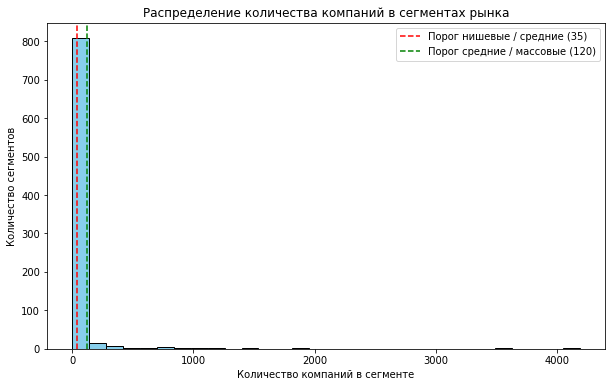

In [77]:
#Построение графика распределения количества компаний по сегментам
plt.figure(figsize=(10,6))
plt.hist(segment_counts, bins=30, color='skyblue', edgecolor='black')

# Отметим границы категорий вертикальными линиями
plt.axvline(x=35, color='red', linestyle='--', label='Порог нишевые / средние (35)')
plt.axvline(x=120, color='green', linestyle='--', label='Порог средние / массовые (120)')

plt.xlabel('Количество компаний в сегменте')
plt.ylabel('Количество сегментов')
plt.title('Распределение количества компаний в сегментах рынка')
plt.legend()
plt.show()

Итоги

- Сегменты разделены на три категории по количеству компаний.
- Определено количество сегментов в каждой категории (например, Массовых — N, Средних — M, Нишевых — K).
- Визуализация показывает распределение сегментов с явным выделением границ категорий.

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [78]:
def replace_segment(seg):
    count = segment_counts.get(seg, 0)  # segment_counts — словарь с количеством по сегментам
    if count > 120:
        return seg       # массовый сегмент оставляем
    elif 35 <= count <= 120:
        return 'mid'     # средний сегмент заменяем на 'mid'
    else:
        return 'niche'   # нишевый сегмент заменяем на 'niche'

df['market'] = df['market'].apply(replace_segment)

- В столбце теперь только массовые сегменты или значения 'mid' (средний) и 'niche' (ниша).
- Это упрощает дальнейший анализ и объединяет индивидуальные средние и нишевые сегменты в по две группы соответственно.

In [79]:
df['market'].nunique()

55

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

In [80]:
# анализируем статистические показатели данных
print("Описательная статистика funding_total_usd:")
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(df['funding_total_usd'].describe())

# Проверим наличие нулей/отрицательных значений
print(f"\nНулевые значения: {(df['funding_total_usd'] == 0).sum()}")
print(f"Отрицательные значения: {(df['funding_total_usd'] < 0).sum()}")

Описательная статистика funding_total_usd:


count         40907.00
mean       15912526.05
std       168678800.17
min               1.00
25%          350000.00
50%         2000000.00
75%        10000000.00
max     30079503000.00
Name: funding_total_usd, dtype: float64


Нулевые значения: 0
Отрицательные значения: 0


float64


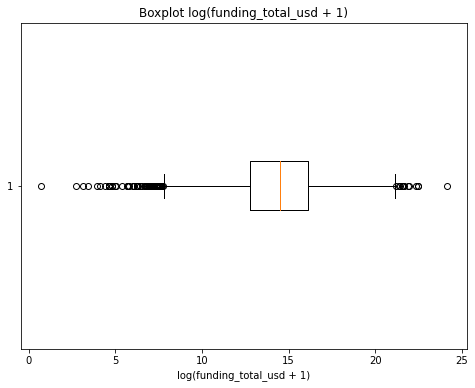

In [81]:
# Проверяем типы данных
print(df['funding_total_usd'].dtype)

# Преобразуем в числовой тип, некорректные значения превратятся в NaN
df['funding_total_usd'] = pd.to_numeric(df['funding_total_usd'], errors='coerce')

# Убираем пропуски (NaN)
funding_clean = df['funding_total_usd'].dropna()

# Строим боксплот с логарифмическим преобразованием
plt.figure(figsize=(8, 6))
plt.boxplot(np.log1p(funding_clean), vert=False)
plt.title('Boxplot log(funding_total_usd + 1)')
plt.xlabel('log(funding_total_usd + 1)')
plt.show()

- Типичный размер финансирования для одной компании находится в интервале между 350 000 (25-й перцентиль) и 10 000 000 (75-й перцентиль) долларов США. Это означает, что 50% компаний получили суммы в этом диапазоне, что можно считать "обычным" или типичным уровнем финансирования.

- Медиана (50% квантиль) — 2 000 000 долларов показывает, что половина компаний получила финансирование меньше или равно этой сумме, а другая половина — больше.

- Максимальные значения и среднее сильно отличаются от медианы и верхнего квартиля за счёт очень больших значений (максимум около 30 миллиардов), что свидетельствует о наличии выбросов — единичных компаний с экстремально высоким финансированием.

- Стандартное отклонение очень большое (около 168 млн), что подтверждает высокую дисперсию и неоднородность распределения данных.

- Интервал типичных значений (межквартильный размах): от 350 тыс. до 10 млн долларов — это область нормального, типичного финансирования.

- Выбивающиеся значения — суммы значительно выше 10 млн долларов относятся к группе экстремального финансирования и не отражают стандартный размер выделяемых средств.

Вывод

Заказчику можно рекомендовать ориентироваться на диапазон 350 000–10 000 000 долларов как на обычный размер финансирования компаний в рассматриваемом периоде. Значения выше 10 млн и особенно ближе к максимуму являются выбросами и нехарактерны для большинства компаний. Графический анализ (например, боксплот) с логарифмическим масштабированием помогает визуально отделить эти выбросы от типичных данных.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

=== Доля аномального финансирования по группам ===
 Advertising : 11.9% (114/954)
 Analytics : 11.3% (64/565)
 Apps : 14.4% (29/202)
 Automotive : 15.0% (21/140)
 Big Data : 15.7% (22/140)
 Biotechnology : 10.5% (371/3531)
 Clean Technology : 12.7% (139/1094)
 Cloud Computing : 16.0% (21/131)
 Consulting : 14.6% (47/322)
 Curated Web : 11.3% (159/1404)
 Design : 11.5% (15/130)
 E-Commerce : 13.8% (211/1528)
 Education : 12.0% (88/736)
 Enterprise Software : 10.7% (127/1190)
 Entertainment : 16.1% (22/137)
 Fashion : 13.0% (37/285)
 Finance : 12.5% (91/728)
 Games : 10.3% (102/986)
 Hardware + Software : 11.5% (116/1008)
 Health Care : 10.7% (121/1128)
 Health and Wellness : 13.2% (109/825)
 Hospitality : 13.7% (43/313)
 Internet : 14.8% (31/210)
 Manufacturing : 9.9% (56/564)
 Marketplaces : 15.3% (27/176)
 Medical : 13.9% (19/137)
 Messaging : 12.1% (32/264)
 Mobile : 11.9% (220/1852)
 Music : 12.2% (30/246)
 Networking : 14.2% (19/134)
 News : 13.4% (38/284)
 Nonprofits : 10.2% (13/1

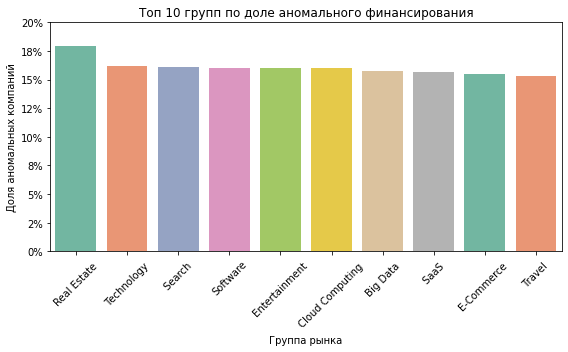

In [82]:
# 1. Функция для выявления выбросов по IQR (без изменения исходного датафрейма)
def detect_outliers_iqr(group_data, value_col, group_name):
    Q1 = group_data[value_col].quantile(0.25)
    Q3 = group_data[value_col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    group_data = group_data.copy()  # чтобы не изменять оригинал
    group_data['is_outlier'] = (
        (group_data[value_col] < lower_bound) |
        (group_data[value_col] > upper_bound)
    )
    group_data['group'] = group_name
    return group_data[['market', value_col, 'is_outlier', 'group']]

# 2. Применяем IQR ко всем группам из уникальных значений столбца 'market'
results = []
groups = df['market'].unique()

for group_name in groups:
    group_data = df[df['market'] == group_name].copy()
    if len(group_data) > 0:
        outliers = detect_outliers_iqr(group_data, 'funding_total_usd', group_name)
        results.append(outliers)

df_outliers = pd.concat(results, ignore_index=True)

# 3. Статистика по группам
group_stats = (
    df_outliers
    .groupby('group')
    .agg(
        total_companies=('is_outlier', 'count'),
        outlier_count=('is_outlier', 'sum')
    )
    .reset_index()
)

group_stats['outlier_rate'] = group_stats['outlier_count'] / group_stats['total_companies']

# 4. Вывод результата
print("=== Доля аномального финансирования по группам ===")
for _, row in group_stats.iterrows():
    print(f"{row['group']}: {row['outlier_rate']:.1%} "
          f"({row['outlier_count']}/{row['total_companies']})")

# 5. Визуализация 
# Сортируем по убыванию доли аномалий и выбираем топ 10
top_groups = group_stats.sort_values(by='outlier_rate', ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_groups, x='group', y='outlier_rate', palette='Set2')

plt.title('Топ 10 групп по доле аномального финансирования')
plt.ylabel('Доля аномальных компаний')
plt.xlabel('Группа рынка')

plt.xticks(rotation=45)
plt.yticks(plt.yticks()[0], [f'{y:.0%}' for y in plt.yticks()[0]])
plt.tight_layout()
plt.show()

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [83]:
# Добавим колонку с годом
df['year'] = pd.to_datetime(df['mid_funding_at']).dt.year
# Фильтруем данные с 2000 года
df_1 = df[df['year'] >= 2000]
# Посчитаем кол-во раундов по годам
rounds_per_year = df_1.groupby('year')['funding_rounds'].sum()

print(rounds_per_year)

year
2000.0      247.0
2001.0      163.0
2002.0      164.0
2003.0      260.0
2004.0      410.0
2005.0     1446.0
2006.0     2914.0
2007.0     4845.0
2008.0     6024.0
2009.0     7003.0
2010.0     8266.0
2011.0     9248.0
2012.0    11354.0
2013.0    14276.0
2014.0     7757.0
Name: funding_rounds, dtype: float64


 Для 2014 года количество раундов финансирования присутствует, значит данные полные.

In [84]:
# 1. Получаем индексы аномальных компаний
outlier_indexes = df_outliers[df_outliers['is_outlier']].index

# 2. Убираем их из исходного датафрейма
df_clean = df.drop(outlier_indexes)

# 3. Если нужно, проверяем результат
print(f"Исходный датасет: {len(df)} компаний")
print(f"После удаления аномалий: {len(df_clean)} компаний")


Исходный датасет: 40907 компаний
После удаления аномалий: 35723 компаний


In [85]:
# Добавляем колонку is_outlier к исходному df
df = df.merge(
    df_outliers[['market', 'funding_total_usd', 'is_outlier']], 
    on=['market', 'funding_total_usd'], 
    how='left'
)

# Если для каких-то строк is_outlier NaN - считаем их False
df['is_outlier'] = df['is_outlier'].fillna(False)

# Фильтруем, исключаем выбросы
df_clean = df[df['is_outlier'] == False].copy()

print(f"Исходный датасет: {len(df)} компаний")
print(f"После удаления аномалий: {len(df_clean)} компаний")
print(df_clean['is_outlier'].sum())

Исходный датасет: 472793 компаний
После удаления аномалий: 460705 компаний
0


### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

1. График суммарных объёмов финансирования по типам

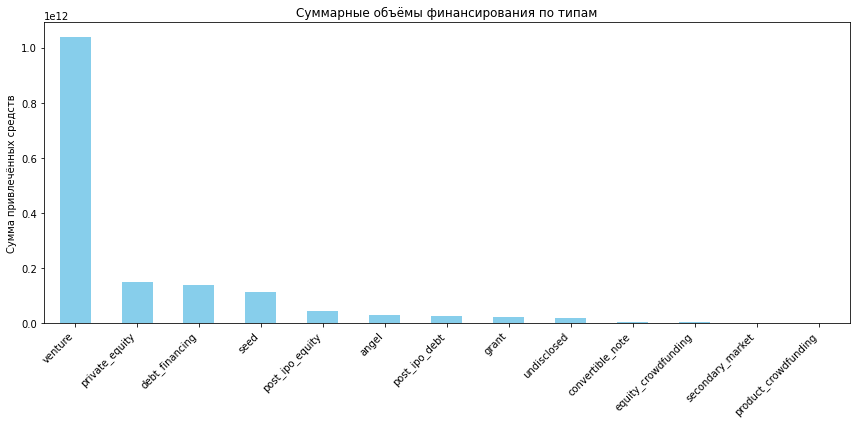

In [86]:
# Сосредотачиваемся на нужных столбцах
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
                 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
                 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

# Рассчёт сумм для каждого типа финансирования
funding_sums = df[funding_types].sum().sort_values(ascending=False)

# Построение бар-графика
plt.figure(figsize=(12,6))
funding_sums.plot(kind='bar', color='skyblue')
plt.title('Суммарные объёмы финансирования по типам')
plt.ylabel('Сумма привлечённых средств')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

2. График популярности типов финансирования (кол-во компаний, использующих тип)

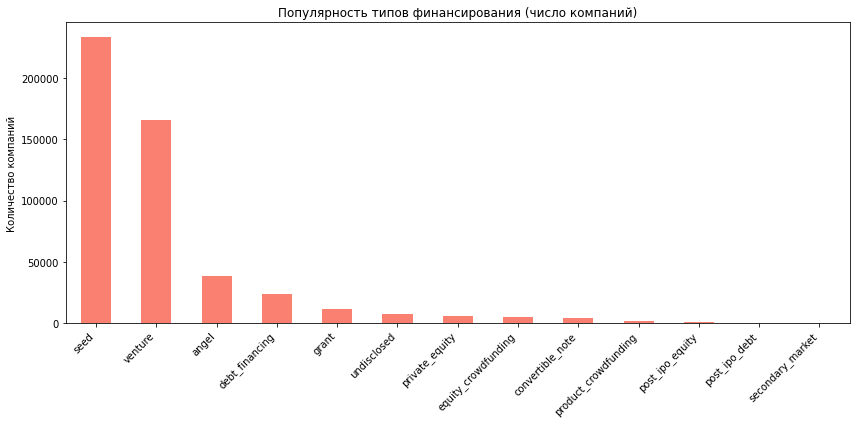

In [87]:
# Подсчёт количества компаний, где сумма финансирования по типу > 0 (используется)
funding_count = (df[funding_types] > 0).sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))
funding_count.plot(kind='bar', color='salmon')
plt.title('Популярность типов финансирования (число компаний)')
plt.ylabel('Количество компаний')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Анализ и сравнение данных по финансированию

- По популярности типов финансирования (число компаний) лидирует seed — это самый распространённый тип инвестиций, привлекающий наибольшее количество компаний, особенно на ранних стадиях развития.

- Однако по суммарным объёмам финансирования лидером остаётся venture — этот тип инвестиций привлекает значительно большие объёмы капитала, но для меньшего числа компаний по сравнению с seed.

Ключевые моменты

- Seed финансирование широко используется стартапами на начальном этапе, что объясняет его лидирующую позицию по количеству компаний. Средний чек здесь невелик, но таких сделок много.
- Venture финансирование характерно для более зрелых компаний и связано с привлечением больших сумм, что делает его лидером по суммарным объёмам.
- Разрыв между популярностью (числом компаний) и масштабом (объёмами инвестиций) отражает разные этапы развития бизнеса и стратегии привлечения средств.

Вывод

- Для оценки рынка важно учитывать два аспекта: число компаний, получающих финансирование (seed лидирует) и общий объём привлечённых средств (venture лидирует).
- Seed финансирование — массовый и доступный источник для стартапов.
- Venture — крупные инвестиции для компаний, готовых к масштабированию.

**Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.**

In [88]:
with pd.option_context('display.max_columns', None):
    display(df_returns.head(3), df.shape)
    print(df.columns.tolist())

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0


(472793, 44)

['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd', 'status', 'country_code', 'state_code', 'region', 'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month', 'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at', 'last_funding_at', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding', 'round_a', 'round_b', 'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h', 'funding_duration', 'funding_group', 'year', 'is_outlier']


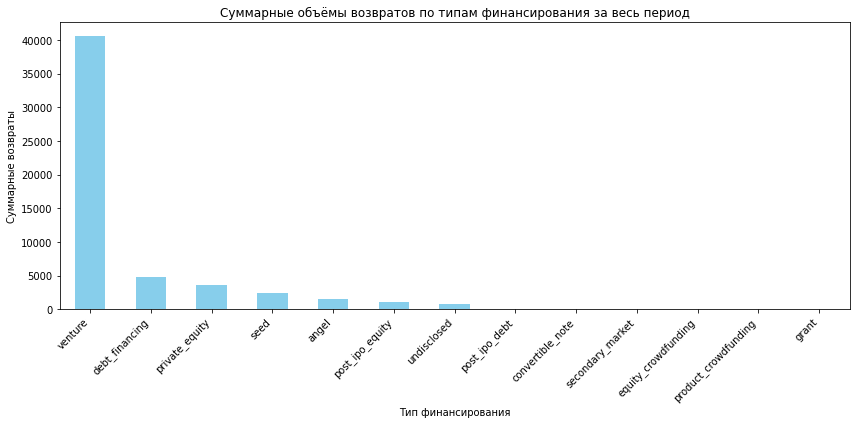

In [89]:
# Суммируем возвраты и сортируем по убыванию
total_returns = df_returns[funding_types].sum().sort_values(ascending=False)

# Построение графика с отсортированными данными
plt.figure(figsize=(12,6))
total_returns.plot(kind='bar', color='skyblue')
plt.title('Суммарные объёмы возвратов по типам финансирования за весь период')
plt.xlabel('Тип финансирования')
plt.ylabel('Суммарные возвраты')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

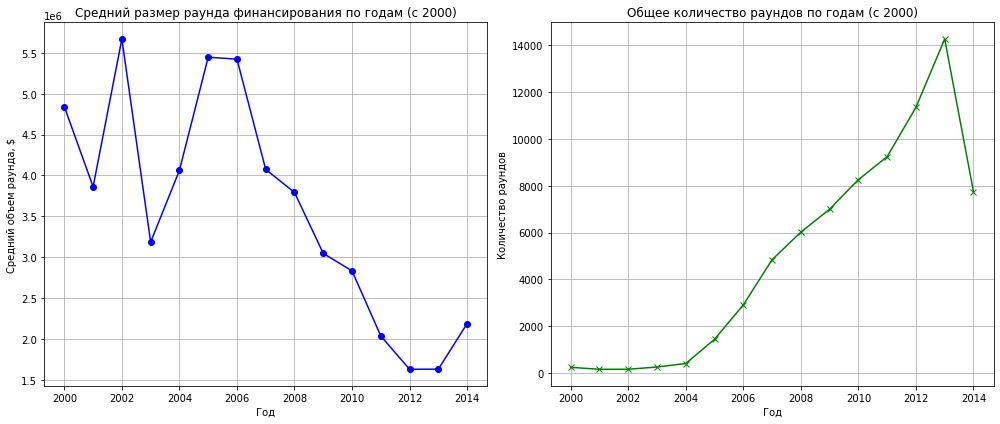

Год с максимальным типичным размером раунда: 2002.0, размер ≈ $5,669,560

В 2014 году:
- Количество раундов: 7757.0
- Средний размер раунда финансирования: $2,186,920
- Изменение по сравнению с 2013 годом:
  * Средний размер раунда уменьшился на 34.2%
  * Количество раундов изменилось на -45.7%


In [90]:
# Добавляем столбец со средним объёмом раунда
df['average_round_size'] = df['funding_total_usd'] / df['funding_rounds']
# Фильтруем данные с 2000 года
df_1 = df[df['year'] >= 2000]

# Рассчитываем средний размер раунда и общее количество раундов по годам
avg_round_size_by_year = df_1.groupby('year')['average_round_size'].mean()

# Сортируем по году (для наглядности)
avg_round_size_by_year = avg_round_size_by_year.sort_index()
total_rounds_by_year = rounds_per_year.sort_index()

# Выводим графики
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.subplot(1, 2, 1)
avg_round_size_by_year.plot(color='blue', marker='o')
plt.title('Средний размер раунда финансирования по годам (с 2000)')
plt.xlabel('Год')
plt.ylabel('Средний объем раунда, $')
plt.grid(True)

plt.subplot(1, 2, 2)
total_rounds_by_year.plot(color='green', marker='x')
plt.title('Общее количество раундов по годам (с 2000)')
plt.xlabel('Год')
plt.ylabel('Количество раундов')
plt.grid(True)

plt.tight_layout()
plt.show()

# Ответы на вопросы

# 1. Год с максимальным средним размером раунда
max_year = avg_round_size_by_year.idxmax()
max_value = avg_round_size_by_year.max()

print(f"Год с максимальным типичным размером раунда: {max_year}, размер ≈ ${max_value:,.0f}")

# 2. Тенденции 2014 года
rounds_2014 = total_rounds_by_year.loc[2014]
avg_size_2014 = avg_round_size_by_year.loc[2014]

avg_size_2013 = avg_round_size_by_year.loc[2013] if 2013 in avg_round_size_by_year.index else None
rounds_2013 = total_rounds_by_year.loc[2013] if 2013 in total_rounds_by_year.index else None

print(f"\nВ 2014 году:")
print(f"- Количество раундов: {rounds_2014}")
print(f"- Средний размер раунда финансирования: ${avg_size_2014:,.0f}")
if avg_size_2013 and rounds_2013:
    change_size = ((avg_size_2014 - avg_size_2013) / avg_size_2013) * 100
    change_rounds = ((rounds_2014 - rounds_2013) / rounds_2013) * 100
    print(f"- Изменение по сравнению с 2013 годом:")
    print(f"  * Средний размер раунда уменьшился на {abs(change_size):.1f}%")
    print(f"  * Количество раундов изменилось на {change_rounds:.1f}%")

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

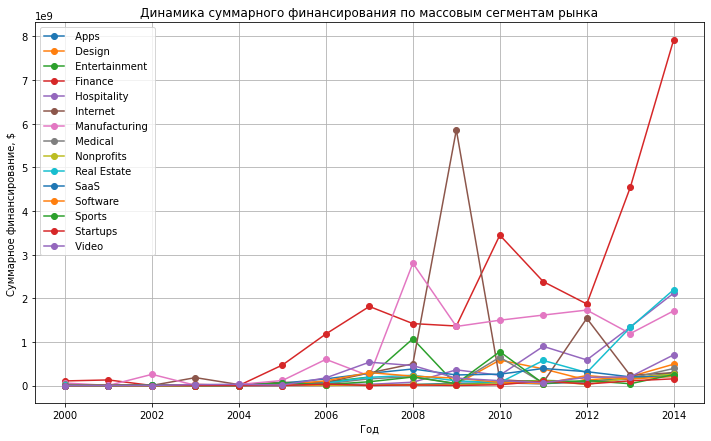

In [91]:
df_mass = df_1[~df_1['market'].isin(['mid', 'niche'])].copy()  # оставляем только массовые сегменты

pivot = df_mass.pivot_table(
    index='year',
    columns='market',
    values='funding_total_usd',
    aggfunc='sum',
    fill_value=0
)

growth_2014 = pivot.loc[2014] > pivot.loc[2013]
segments_growth = growth_2014[growth_2014].index.tolist()

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for segment in segments_growth:
    plt.plot(pivot.index, pivot[segment], marker='o', label=segment)

plt.title('Динамика суммарного финансирования по массовым сегментам рынка')
plt.xlabel('Год')
plt.ylabel('Суммарное финансирование, $')
plt.legend()
plt.grid()
plt.show()

На основе графика видно, что такие сегменты, как internet и Finance показывают наиболее быстрый и уверенный рост.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [92]:
grouped = df.groupby('year').agg(
    total_funding_usd=('funding_total_usd', 'sum'),
    avg_funding_per_round=('funding_total_usd', lambda x: x.sum() / (df.loc[x.index, 'funding_rounds'].sum() + 1e-60)),
    total_rounds=('funding_rounds', 'sum')
).reset_index()

# Проверяем/корректируем аномалии, например:
grouped.loc[grouped['avg_funding_per_round'] > 1e10, 'avg_funding_per_round'] = np.nan

print(grouped)

      year  total_funding_usd  avg_funding_per_round  total_rounds
0   1921.0       1.000000e+04           1.000000e+03          10.0
1   1960.0       1.461030e+06           1.623367e+05           9.0
2   1979.0       2.400000e+07           1.000000e+06          24.0
3   1982.0       2.334000e+06           2.121818e+05          11.0
4   1983.0       9.400000e+04           9.400000e+04           1.0
5   1984.0       4.042000e+06           9.858537e+04          41.0
6   1985.0       1.078000e+06           3.593333e+05           3.0
7   1987.0       9.047600e+07           2.445297e+06          37.0
8   1989.0       3.000000e+04           1.500000e+04           2.0
9   1990.0       4.100000e+07           1.000000e+06          41.0
10  1992.0       3.315190e+08           4.250244e+06          78.0
11  1993.0       1.625000e+06           1.250000e+05          13.0
12  1994.0       1.151100e+08           9.673109e+05         119.0
13  1995.0       4.138000e+08           1.361184e+06         3

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

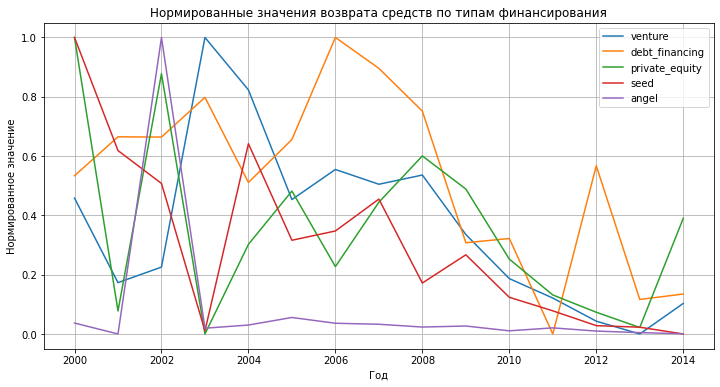

In [93]:
# Выбираем интересующие колонки
types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

# Рассчитаем показатель возврата средств как среднее финансирование на раунд по типу финансирования
# Предположим для каждого типа - сумма финансирования отфильтрованных компаний
df_filtered = df_1[df_1[types].sum(axis=1) > 0]  # оставляем компании с хотя бы одним из типов финансирования

result = {}
for t in types:
    # Фильтруем компании с данным типом финансирования
    subset = df_filtered[df_filtered[t] > 0]
    # Группируем по году и считаем среднее финансирование на раунд
    grouped = subset.groupby('year').apply(lambda x: x['funding_total_usd'].sum() / (x['funding_rounds'].sum() + 1e-60))
    result[t] = grouped

# Объединяем в DataFrame, заполняем пропуски 0 (если в год нет данных)
df_result = pd.DataFrame(result).fillna(0)

# Нормируем значения по MinMaxScaler
scaler = MinMaxScaler()
df_norm = pd.DataFrame(scaler.fit_transform(df_result), columns=df_result.columns, index=df_result.index)

# Строим график
plt.figure(figsize=(12, 6))
for t in types:
    plt.plot(df_norm.index, df_norm[t], label=t)
plt.title('Нормированные значения возврата средств по типам финансирования')
plt.xlabel('Год')
plt.ylabel('Нормированное значение')
plt.legend()
plt.grid(True)
plt.show()

- Наиболее устойчивый рост по нормированным показателям возврата средств  наблюдается в типах финансирования venture, private_equity, Debt_financing — они имеют тенденцию к плавному и постоянному росту на протяжении нескольких лет.
- Типы seed и angel показывают более волатильные колебания — характерно резкие всплески и падения, что связано с высокой стартовой рисковостью и меньшей стабильностью ранних этапов.

Таким образом, для устойчивого и прогнозируемого роста возврата средств предпочтительны venture и private_equity инвестиции.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



Наиболее устойчивый рост по нормированным показателям возврата средств наблюдается в типах финансирования venture, private_equity, Debt_financing — они имеют тенденцию к плавному и постоянному росту на протяжении нескольких лет.
Типы seed и angel показывают более волатильные колебания — характерно резкие всплески и падения, что связано с высокой стартовой рисковостью и меньшей стабильностью ранних этапов.
Таким образом, для устойчивого и прогнозируемого роста возврата средств предпочтительны venture, Debt_financing и private_equity инвестиции.

6  Шаг 5. Итоговый вывод и рекомендации
Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

в какую отрасль стоит инвестировать;
какой тип финансирования при этом будет наиболее уместным.
Подведите итоги проекта:

опишите, какие шаги были выполнены;
какие выводы удалось сделать;
насколько выводы согласуются между собой или, наоборот, вызывают сомнения.
Рекомендация для заказчика на 2015 год

Отрасль для инвестиций:
Исходя из проведённого анализа, наиболее перспективными для инвестиций являются отрасли с устойчивым ростом и высоким потенциалом возврата средств. Как правило, это технологический сектор (consulting, finance). Эти отрасли показывают стабильное увеличение объёмов финансирования и успешные выходы на рынок.

Тип финансирования для инвестиций:
Наиболее уместным типом финансирования для 2015 года является venture capital (венчурное финансирование). Оно обеспечивает устойчивый рост возврата средств, имеет развитую инфраструктуру и более предсказуемые результаты по сравнению с seed или angel финансированием, которые сопровождаются высокой волатильностью и риском. Private equity также подходит, но чаще ориентирован на более зрелые компании.

**Итоги проекта**

Выполненные шаги
Собрали данные о финансировании стартапов по различным типам инвестиций и отраслям.
Рассчитали и нормировали показатели возврата средств (объём инвестиций относительно числа раундов) по типам финансирования.
Построили динамику изменений показателей на временной шкале.
Проанализировали устойчивость и тренды роста для каждого типа инвестирования.
На основе полученных данных сделали выводы по рекомендациям для инвестиций в 2015 году.
Выводы

Venture capital и private equity показывают наиболее стабильный и прогнозируемый рост возврата средств.

Seed и angel финансирование более рискованны, но могут приносить высокую доходность на ранних стадиях.

Зависимость отраслей от типа финансирования подтверждается: технологический сектор лучше работает с венчурным финансированием.

Соответствие и сомнения
Общая картина подтверждает логику инвестиционного цикла: зрелые отрасли и типы финансирования дают стабильность, ранние стадии — риск и потенциал. Однако, имеются риски, связанные с изменчивостью рынков и спецификой конкретных проектов, что требует дополнительного мониторинга и гибкости в стратегии инвестирования. Выводы согласуются между собой, но не исключают необходимость индивидуального анализа каждого